# 22.2 - Tri-Model Spatiotemporal Master Ensemble + 4-View TTA
## Tai Phake Visual Speech Recognition (VSR) Project

### 1. Executive Overview & Architectural Inductive Biases
In word-level silent lip reading of fine-grained numerical digits under strict speaker-independent evaluation (80/20 train/val split across distinct speakers), single spatiotemporal architectures encounter distinctive structural limitations:

1. **Model A (Notebook 19) — EfficientNet-B0 + Absolute Optical Differences ($|F_t - F_{t-1}|$) + BiGRU + 5 Snapshots**:
   - **Input Channel**: 4-channel $(30, 96, 96, 4)$ with unsigned temporal motion energy.
   - **Key Competencies**: Dominates high-speed ballistic dental and bilabial closures: $d_0$ (*Pau*, 95% F1), $d_8$ (*Pet*, 95% F1), $d_{10}$ (*Sip*, 75% recall).
   - **Validation Accuracy**: 70.45% (155/220).

2. **Model B (Notebook 13) — MobileNetV2 + BiLSTM + Learnable Attention Pooling**:
   - **Input Channel**: Standard 3-channel RGB $(30, 96, 96, 3)$ with linear inverted bottleneck spatial representations.
   - **Key Competencies**: Exceptional aspect-ratio tracking of broad horizontal mouth opening; achieves top performance on $d_2$ (*Saung*, **85% recall** vs 50% in EffNet) and tough speakers ($S35$, **65.9%**).
   - **Validation Accuracy**: 68.18% (150/220).

3. **Model C (Notebook 22) — EfficientNet-B0 + Utterance Speaker Neutralizer + Signed Centered Motion + Tri-Window Phonetic Attention + 5 Snapshots**:
   - **Input Channel**: 4-channel $(30, 96, 96, 4)$ with signed direction-preserving motion ($127.5 + 0.5(F_t - F_{t-1})$).
   - **Speaker Invariance**: Learned gate subtracts utterance temporal mean, neutralizing speaker-specific skin tone and resting mouth morphology.
   - **Phonetic Tri-Window**: Explicitly decouples Onset (Frames 0..11), Nucleus (Frames 9..20), and Coda (Frames 18..29) temporal attention pools.
   - **Key Competencies**: Dominates difficult unseen speakers ($S35$ jumps from 59.1% to **72.7%**, $s45$ from 60.6% to **69.7%**), and excels on $d_7$ (*Chit*, **55% recall**), $d_1$ (*Nung*, 70%), $d_3$ (*Sam*, 90%), $d_4$ (*Si*, 75%).
   - **Validation Accuracy**: 69.09% (152/220).

---

### 2. Tri-Model Soft-Voting Ensemble Formulation
Each model evaluates 4 Test-Time Augmentation (TTA) views (Identity, Temporal Shift $+1$, Temporal Shift $-1$, Horizontal Flip) across its checkpoint snapshots. 
The final class probability vector $\hat{P} \in \Delta^{10}$ is formed via convex linear combination on the 2D probability simplex:

$$\hat{P}(y = k \mid X) = w_A \cdot P_A(k \mid X) + w_B \cdot P_B(k \mid X) + w_C \cdot P_C(k \mid X)$$
$$\text{subject to } w_A + w_B + w_C = 1.0, \quad w_A, w_B, w_C \ge 0$$


## 1. Environment & Imports
Loading TensorFlow, Keras 3, image processing libraries, and scientific evaluation tooling.


In [1]:
import os
import re
import json
import random
import time
from pathlib import Path
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
import keras
from keras import layers
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

print("=" * 80)
print("TRI-MODEL MASTER ENSEMBLE + 4-VIEW TTA INFERENCE PIPELINE")
print("=" * 80)
print(f"TensorFlow Version : {tf.__version__}")
print(f"Keras Version      : {keras.__version__}")
print(f"Random Seed        : {SEED}")
print("=" * 80)


TRI-MODEL MASTER ENSEMBLE + 4-VIEW TTA INFERENCE PIPELINE
TensorFlow Version : 2.21.0
Keras Version      : 3.15.1
Random Seed        : 42


## 2. Paths & Directory Configuration
Setting paths to the active processed validation set (`data/processed/val`) and the checkpoints for Notebooks 19, 13, and 22.


In [2]:
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR

DATA_DIR = PROJECT_ROOT / "data" / "processed"
VAL_DIR = DATA_DIR / "val"

NB19_DIR = PROJECT_ROOT / "results" / "efficientnetb0_bigru_motion_focal_snapshot_80_20"
NB13_DIR = PROJECT_ROOT / "results" / "mobilenetv2_bilstm_attention_pooling_80_20"
NB22_DIR = PROJECT_ROOT / "results" / "efficientnetb0_bigru_triwindow_signed_motion_80_20"

RESULTS_DIR = PROJECT_ROOT / "results" / "ensemble_tri_model_80_20"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

NUM_CLASSES = 11
NUM_FRAMES = 30
FRAME_WIDTH = 96
FRAME_HEIGHT = 96
CLASS_TO_ID = {f"d{i}": i for i in range(NUM_CLASSES)}
ID_TO_CLASS = {i: f"d{i}" for i in range(NUM_CLASSES)}

DIGIT_NAMES = [
    "d0 (Pau)", "d1 (Nung)", "d2 (Saung)", "d3 (Sam)", "d4 (Si)",
    "d5 (Ha)", "d6 (Hok)", "d7 (Chit)", "d8 (Pet)", "d9 (Kao)", "d10 (Sip)"
]

print(f"Validation directory : {VAL_DIR}")
print(f"Results directory    : {RESULTS_DIR}")


Validation directory : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/data/processed/val
Results directory    : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/ensemble_tri_model_80_20


## 3. Validation Manifest & Data Ingestion
Enumerating all 220 validation utterances across the 20 speaker directories (6 base validation speakers: `s34, S35, S38, s45, s47, s48`).


In [3]:
val_speakers = sorted([d.name for d in VAL_DIR.iterdir() if d.is_dir() and not d.name.startswith(".")])
utterances = []

for spk in val_speakers:
    spk_path = VAL_DIR / spk
    base_spk = spk.split("_")[0]
    for digit_dir in sorted(spk_path.iterdir()):
        if not digit_dir.is_dir() or digit_dir.name.startswith("."):
            continue
        digit_name = digit_dir.name
        if digit_name not in CLASS_TO_ID:
            continue
        frames = sorted([f for f in digit_dir.iterdir() if f.is_file() and f.suffix.lower() in [".jpg", ".jpeg", ".png"]])
        if len(frames) == 0:
            continue
        utterances.append({
            "speaker": spk,
            "base_speaker": base_spk,
            "digit": digit_name,
            "digit_id": CLASS_TO_ID[digit_name],
            "frame_paths": frames
        })

df_val = pd.DataFrame(utterances)
N = len(df_val)
y_val = np.array(df_val["digit_id"].values, dtype=np.int32)

print(f"Total Validation Utterances: {N}")
print(f"Speaker Directories: {len(val_speakers)}")
print(f"Unique Base Speakers: {sorted(df_val['base_speaker'].unique())}")
print("Utterances per Base Speaker:")
print(df_val["base_speaker"].value_counts().sort_index())


Total Validation Utterances: 220
Speaker Directories: 20
Unique Base Speakers: ['S35', 'S38', 's34', 's45', 's47', 's48']
Utterances per Base Speaker:
base_speaker
S35    44
S38    33
s34    44
s45    33
s47    33
s48    33
Name: count, dtype: int64


## 4. Precomputing Multimodal Input Tensors
To ensure fast execution across all 3 architectures, we precompute:
1. `X_val_3ch`: Standard RGB tensor $(N, 30, 96, 96, 3)$ for MobileNetV2.
2. `X_val_4ch_abs`: 4-channel tensor with unsigned optical difference $|F_t - F_{t-1}|$ for Notebook 19.
3. `X_val_4ch_signed`: 4-channel tensor with signed centered motion $127.5 + 0.5(F_t - F_{t-1})$ for Notebook 22.


In [4]:
def sample_30_frame_paths(frame_paths: list) -> list:
    n = len(frame_paths)
    indices = np.round(np.linspace(0, n - 1, NUM_FRAMES)).astype(int) if n != NUM_FRAMES else list(range(NUM_FRAMES))
    return [str(frame_paths[i]) for i in indices]

def compute_abs_frame_diff(seq_rgb: np.ndarray) -> np.ndarray:
    T, H, W, _ = seq_rgb.shape
    gray = (0.2989 * seq_rgb[..., 0] + 0.5870 * seq_rgb[..., 1] + 0.1140 * seq_rgb[..., 2])[..., np.newaxis]
    diff = np.zeros((T, H, W, 1), dtype=np.float32)
    diff[1:] = np.abs(gray[1:] - gray[:-1])
    return np.concatenate([seq_rgb, diff], axis=-1)

def compute_signed_frame_diff(seq_rgb: np.ndarray) -> np.ndarray:
    T, H, W, _ = seq_rgb.shape
    gray = (0.2989 * seq_rgb[..., 0] + 0.5870 * seq_rgb[..., 1] + 0.1140 * seq_rgb[..., 2])[..., np.newaxis]
    diff = np.full((T, H, W, 1), 127.5, dtype=np.float32)
    diff[1:] = np.clip(127.5 + 0.5 * (gray[1:] - gray[:-1]), 0.0, 255.0)
    return np.concatenate([seq_rgb, diff], axis=-1)

X_val_3ch = np.zeros((N, NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, 3), dtype=np.float32)
X_val_4ch_abs = np.zeros((N, NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, 4), dtype=np.float32)
X_val_4ch_signed = np.zeros((N, NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, 4), dtype=np.float32)

t0 = time.time()
for i, row in df_val.iterrows():
    sampled = sample_30_frame_paths(row["frame_paths"])
    rgb_seq = np.zeros((NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, 3), dtype=np.float32)
    for t, fp in enumerate(sampled):
        im = Image.open(fp).convert("RGB")
        if im.size != (FRAME_WIDTH, FRAME_HEIGHT):
            im = im.resize((FRAME_WIDTH, FRAME_HEIGHT), Image.BILINEAR)
        rgb_seq[t] = np.array(im, dtype=np.float32)
    X_val_3ch[i] = rgb_seq
    X_val_4ch_abs[i] = compute_abs_frame_diff(rgb_seq)
    X_val_4ch_signed[i] = compute_signed_frame_diff(rgb_seq)

print(f"Precomputed {N} utterances for 3 tensor formats in {time.time() - t0:.2f}s!")
print(f"X_val_3ch        : {X_val_3ch.shape}, min={X_val_3ch.min():.1f}, max={X_val_3ch.max():.1f}")
print(f"X_val_4ch_abs    : {X_val_4ch_abs.shape}, min={X_val_4ch_abs.min():.1f}, max={X_val_4ch_abs.max():.1f}")
print(f"X_val_4ch_signed : {X_val_4ch_signed.shape}, min={X_val_4ch_signed.min():.1f}, max={X_val_4ch_signed.max():.1f}")


Precomputed 220 utterances for 3 tensor formats in 2.23s!
X_val_3ch        : (220, 30, 96, 96, 3), min=0.0, max=255.0
X_val_4ch_abs    : (220, 30, 96, 96, 4), min=0.0, max=255.0
X_val_4ch_signed : (220, 30, 96, 96, 4), min=0.0, max=255.0


## 5. 4-View Test-Time Augmentation (TTA)
Building the 4 canonical views per utterance:
1. **View 1 (Identity)**: Original sequence $X_{1:30}$
2. **View 2 (Temporal Shift $+1$)**: Forward time-lag sequence
3. **View 3 (Temporal Shift $-1$)**: Backward time-lead sequence
4. **View 4 (Horizontal Flip)**: Spatially mirrored lip contour sequences


In [5]:
def generate_4view_tta(X_seq: np.ndarray) -> List[np.ndarray]:
    v1 = X_seq.copy()
    v2 = np.empty_like(X_seq)
    v2[:-1] = X_seq[1:]
    v2[-1] = X_seq[-1]
    v3 = np.empty_like(X_seq)
    v3[0] = X_seq[0]
    v3[1:] = X_seq[:-1]
    v4 = np.flip(X_seq, axis=2).copy()
    return [v1, v2, v3, v4]

views_3ch = [np.zeros_like(X_val_3ch) for _ in range(4)]
views_4ch_abs = [np.zeros_like(X_val_4ch_abs) for _ in range(4)]
views_4ch_signed = [np.zeros_like(X_val_4ch_signed) for _ in range(4)]

for i in range(N):
    v3 = generate_4view_tta(X_val_3ch[i])
    va = generate_4view_tta(X_val_4ch_abs[i])
    vs = generate_4view_tta(X_val_4ch_signed[i])
    for v in range(4):
        views_3ch[v][i] = v3[v]
        views_4ch_abs[v][i] = va[v]
        views_4ch_signed[v][i] = vs[v]

print("4-View TTA tensor batches generated across all 3 modalities.")


4-View TTA tensor batches generated across all 3 modalities.


## 6. Model A: EfficientNet-B0 + Absolute Motion Differences (Notebook 19)
Loading all 5 snapshot checkpoints saved during cosine annealing in Notebook 19 and averaging over 4 TTA views.


In [6]:
@keras.saving.register_keras_serializable()
class TemporalAttentionPooling(layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.score_dense = None
    def build(self, input_shape):
        hidden_dim = input_shape[-1]
        self.score_dense = layers.Dense(1, use_bias=False, name="attn_score")
        super().build(input_shape)
    def call(self, inputs):
        scores = self.score_dense(inputs)
        weights = tf.nn.softmax(scores, axis=1)
        return tf.reduce_sum(inputs * weights, axis=1)

def build_model_a():
    frame_in = keras.Input(shape=(FRAME_HEIGHT, FRAME_WIDTH, 4), name="frame_4ch_input")
    adapter = layers.Conv2D(3, (1, 1), padding="same", use_bias=False, name="motion_stem_adapter")(frame_in)
    base_cnn = keras.applications.EfficientNetB0(weights="imagenet", include_top=False, input_shape=(FRAME_HEIGHT, FRAME_WIDTH, 3))
    preprocessed = keras.applications.efficientnet.preprocess_input(adapter)
    pooled = layers.GlobalAveragePooling2D(name="gap")(base_cnn(preprocessed))
    extractor = keras.Model(inputs=frame_in, outputs=pooled, name="EfficientNetB0_4Ch_Extractor")

    seq_in = keras.Input(shape=(NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, 4), name="sequence_4ch_input")
    x = layers.TimeDistributed(extractor, name="time_distributed_cnn")(seq_in)
    x = layers.Dense(256, activation="relu", name="projection_dense")(x)
    x = layers.Dropout(0.2, name="projection_dropout")(x)
    x = layers.Bidirectional(layers.GRU(128, return_sequences=True, dropout=0.2), name="bidirectional_gru")(x)
    x = TemporalAttentionPooling(name="temporal_attention_pooling")(x)
    x = layers.Dropout(0.4, name="head_dropout")(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax", name="softmax_classification")(x)
    return keras.Model(inputs=seq_in, outputs=out, name="EfficientNetB0_BiGRU_Motion4Ch")

model_a = build_model_a()
snap_paths_a = sorted(list((NB19_DIR / "snapshots").glob("*.weights.h5")))
print(f"Discovered {len(snap_paths_a)} snapshots for Model A:")
for p in snap_paths_a:
    print(f"  • {p.name}")

cache_a = PROJECT_ROOT / "results" / "probs_nb19_tta.npy"
if cache_a.exists():
    probs_a = np.load(cache_a)
    print(f"Loaded precomputed Model A probabilities from {cache_a.name}")
else:
    probs_a_list = []
    for idx, p in enumerate(snap_paths_a, 1):
        model_a.load_weights(p)
        probs_v = [model_a.predict(v, batch_size=16, verbose=0) for v in views_4ch_abs]
        snap_p = np.mean(probs_v, axis=0)
        probs_a_list.append(snap_p)
        snap_acc = np.mean(np.argmax(snap_p, axis=1) == y_val)
        print(f"  -> Snapshot {idx}/5 ({p.name[:28]}): 4-View TTA Acc = {snap_acc * 100:.2f}%")
    probs_a = np.mean(probs_a_list, axis=0)
    np.save(cache_a, probs_a)

acc_a = accuracy_score(y_val, np.argmax(probs_a, axis=1))
print(f"\n[Model A Final] (5-Snapshot + 4-View TTA) Accuracy: {acc_a * 100:.2f}% ({np.sum(np.argmax(probs_a, axis=1) == y_val)}/{N})")


Discovered 5 snapshots for Model A:
  • stage2_epoch_01_loss_0.1730.weights.h5
  • stage2_epoch_02_loss_0.1746.weights.h5
  • stage2_epoch_04_loss_0.1751.weights.h5
  • stage2_epoch_06_loss_0.1739.weights.h5
  • stage2_epoch_09_loss_0.1773.weights.h5
Loaded precomputed Model A probabilities from probs_nb19_tta.npy

[Model A Final] (5-Snapshot + 4-View TTA) Accuracy: 70.45% (155/220)


## 7. Model B: MobileNetV2 + BiLSTM Attention Pooling (Notebook 13)
Loading Stage 2 fine-tuned weights for MobileNetV2 with BiLSTM and learnable attention pooling.


In [7]:
cnn_b = keras.applications.MobileNetV2(input_shape=(FRAME_HEIGHT, FRAME_WIDTH, 3), include_top=False, weights="imagenet", pooling="avg")
in_b = layers.Input(shape=(NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, 3), name="lip_sequence_input")
x = layers.TimeDistributed(layers.Lambda(keras.applications.mobilenet_v2.preprocess_input), name="mobilenetv2_preprocess")(in_b)
x = layers.TimeDistributed(cnn_b, name="mobilenetv2_cnn")(x)
x = layers.TimeDistributed(layers.Dense(256, use_bias=False), name="projection_dense")(x)
x = layers.LayerNormalization(epsilon=1e-6, name="projection_ln")(x)
x = layers.Bidirectional(layers.LSTM(128, return_sequences=True, dropout=0.2), name="bilstm")(x)
attn_s = layers.Dense(1, use_bias=True, name="temporal_attn_score")(x)
attn_w = layers.Softmax(axis=1, name="temporal_attn_weights")(attn_s)
x = layers.Lambda(lambda t: tf.reduce_sum(t[0] * t[1], axis=1), name="temporal_attention_pooling")([x, attn_w])
x = layers.Dropout(0.4, name="head_dropout")(x)
out_b = layers.Dense(NUM_CLASSES, activation="softmax", name="digit_classifier")(x)
model_b = keras.Model(inputs=in_b, outputs=out_b, name="MobileNetV2_BiLSTM_AttentionPooling")

ckpt_b = NB13_DIR / "mobilenetv2_bilstm_attention_pooling_stage2_best.weights.h5"
model_b.load_weights(ckpt_b)
print(f"Loaded Model B weights from: {ckpt_b.name}")

cache_b = PROJECT_ROOT / "results" / "probs_nb13_tta.npy"
if cache_b.exists():
    probs_b = np.load(cache_b)
    print(f"Loaded precomputed Model B probabilities from {cache_b.name}")
else:
    probs_b_v = [model_b.predict(v, batch_size=16, verbose=0) for v in views_3ch]
    probs_b = np.mean(probs_b_v, axis=0)
    np.save(cache_b, probs_b)

acc_b = accuracy_score(y_val, np.argmax(probs_b, axis=1))
print(f"\n[Model B Final] (MobileNetV2 + 4-View TTA) Accuracy: {acc_b * 100:.2f}% ({np.sum(np.argmax(probs_b, axis=1) == y_val)}/{N})")


Loaded Model B weights from: mobilenetv2_bilstm_attention_pooling_stage2_best.weights.h5
Loaded precomputed Model B probabilities from probs_nb13_tta.npy

[Model B Final] (MobileNetV2 + 4-View TTA) Accuracy: 68.18% (150/220)


## 8. Model C: EfficientNet-B0 + Utterance Speaker Neutralizer + Tri-Window (Notebook 22)
Loading the 5 snapshot checkpoints from Notebook 22 with signed motion differences and phonetic tri-window attention.


In [8]:
@keras.saving.register_keras_serializable(package="TaiPhakeVSR")
class UtteranceSpeakerNeutralizer(layers.Layer):
    def __init__(self, init_logit=0.85, **kwargs):
        super().__init__(**kwargs)
        self.init_logit = float(init_logit)
    def build(self, input_shape):
        self.gate_logit = self.add_weight(
            name="speaker_mean_gate_logit",
            shape=(1, 1, input_shape[-1]),
            initializer=keras.initializers.Constant(self.init_logit),
            trainable=True
        )
        super().build(input_shape)
    def call(self, inputs):
        m = tf.reduce_mean(inputs, axis=1, keepdims=True)
        g = tf.nn.sigmoid(self.gate_logit)
        return inputs - g * m

@keras.saving.register_keras_serializable(package="TaiPhakeVSR")
class TemporalAttentionPooling(layers.Layer):
    def __init__(self, attn_units=64, **kwargs):
        super().__init__(**kwargs)
        self.attn_units = attn_units
        self.dense1 = layers.Dense(attn_units, activation="tanh", name="w_attn")
        self.dense2 = layers.Dense(1, use_bias=False, name="u_attn")
    def call(self, inputs):
        s = self.dense1(inputs)
        l = self.dense2(s)
        w = tf.nn.softmax(l, axis=1)
        return tf.reduce_sum(inputs * w, axis=1)

@keras.saving.register_keras_serializable(package="TaiPhakeVSR")
class TriWindowAttentionPooling(layers.Layer):
    def __init__(self, onset_bounds=(0, 12), nucleus_bounds=(9, 21), coda_bounds=(18, 30), attn_units=64, **kwargs):
        super().__init__(**kwargs)
        self.onset_bounds = tuple(onset_bounds)
        self.nucleus_bounds = tuple(nucleus_bounds)
        self.coda_bounds = tuple(coda_bounds)
        self.onset_pool = TemporalAttentionPooling(attn_units=attn_units, name="onset_attn")
        self.nucleus_pool = TemporalAttentionPooling(attn_units=attn_units, name="nucleus_attn")
        self.coda_pool = TemporalAttentionPooling(attn_units=attn_units, name="coda_attn")
    def call(self, inputs):
        xo = inputs[:, self.onset_bounds[0]:self.onset_bounds[1], :]
        xn = inputs[:, self.nucleus_bounds[0]:self.nucleus_bounds[1], :]
        xc = inputs[:, self.coda_bounds[0]:self.coda_bounds[1], :]
        return tf.concat([self.onset_pool(xo), self.nucleus_pool(xn), self.coda_pool(xc)], axis=-1)

def build_model_c():
    frame_in_c = keras.Input(shape=(FRAME_HEIGHT, FRAME_WIDTH, 4), name="frame_4ch_input")
    adapter_c = layers.Conv2D(3, (1, 1), padding="same", use_bias=False, name="signed_motion_adapter")(frame_in_c)
    base_cnn_c = keras.applications.EfficientNetB0(weights="imagenet", include_top=False, input_shape=(FRAME_HEIGHT, FRAME_WIDTH, 3))
    preprocessed_c = keras.applications.efficientnet.preprocess_input(adapter_c)
    pooled_c = layers.GlobalAveragePooling2D(name="gap")(base_cnn_c(preprocessed_c))
    extractor_c = keras.Model(inputs=frame_in_c, outputs=pooled_c, name="EfficientNetB0_4Ch_Extractor")

    seq_in_c = keras.Input(shape=(NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, 4), name="sequence_4ch_input")
    x = layers.TimeDistributed(extractor_c, name="time_distributed_cnn")(seq_in_c)
    x = UtteranceSpeakerNeutralizer(name="utterance_speaker_neutralizer")(x)
    x = layers.LayerNormalization(name="post_neutralizer_ln")(x)
    x = layers.TimeDistributed(layers.Dense(256, activation="swish", name="projection_dense"), name="td_spatial_projection")(x)
    x = layers.SpatialDropout1D(0.20, name="spatial_dropout_1d")(x)
    x = layers.Bidirectional(layers.GRU(128, return_sequences=True, dropout=0.20, name="gru_layer"), name="bigru_temporal_encoder")(x)
    x = layers.LayerNormalization(name="post_bigru_ln")(x)
    x = TriWindowAttentionPooling(name="tri_window_attention_pooling")(x)
    x = layers.BatchNormalization(name="head_bn")(x)
    x = layers.Dropout(0.40, name="head_dropout_1")(x)
    x = layers.Dense(256, activation="swish", name="head_dense_256")(x)
    x = layers.Dropout(0.25, name="head_dropout_2")(x)
    out_c = layers.Dense(NUM_CLASSES, activation="softmax", name="digit_classifier")(x)
    return keras.Model(inputs=seq_in_c, outputs=out_c, name="EfficientNetB0_BiGRU_TriWindow_VSR")

model_c = build_model_c()
snap_paths_c = sorted(list((NB22_DIR / "snapshots").glob("*.weights.h5")))
print(f"Discovered {len(snap_paths_c)} snapshots for Model C:")
for p in snap_paths_c:
    print(f"  • {p.name}")

cache_c = PROJECT_ROOT / "results" / "probs_nb22_tta.npy"
if cache_c.exists():
    probs_c = np.load(cache_c)
    print(f"Loaded precomputed Model C probabilities from {cache_c.name}")
else:
    probs_c_list = []
    for idx, p in enumerate(snap_paths_c, 1):
        model_c.load_weights(p)
        probs_v = [model_c.predict(v, batch_size=16, verbose=0) for v in views_4ch_signed]
        snap_p = np.mean(probs_v, axis=0)
        probs_c_list.append(snap_p)
        snap_acc = np.mean(np.argmax(snap_p, axis=1) == y_val)
        print(f"  -> Snapshot {idx}/5 ({p.name[:28]}): 4-View TTA Acc = {snap_acc * 100:.2f}%")
    probs_c = np.mean(probs_c_list, axis=0)
    np.save(cache_c, probs_c)

acc_c = accuracy_score(y_val, np.argmax(probs_c, axis=1))
print(f"\n[Model C Final] (5-Snapshot + 4-View TTA) Accuracy: {acc_c * 100:.2f}% ({np.sum(np.argmax(probs_c, axis=1) == y_val)}/{N})")


Discovered 5 snapshots for Model C:
  • stage2_epoch_02_acc_0.6727_loss_0.2377.weights.h5
  • stage2_epoch_03_acc_0.6727_loss_0.2323.weights.h5
  • stage2_epoch_07_acc_0.6773_loss_0.2296.weights.h5
  • stage2_epoch_11_acc_0.6727_loss_0.2311.weights.h5
  • stage2_epoch_13_acc_0.6773_loss_0.2290.weights.h5
Loaded precomputed Model C probabilities from probs_nb22_tta.npy

[Model C Final] (5-Snapshot + 4-View TTA) Accuracy: 69.09% (152/220)


## 9. Oracle Complementarity & Error Overlap Analysis
Evaluating the theoretical ceiling of the 3 models by examining the union of correct predictions.


In [9]:
preds_a = np.argmax(probs_a, axis=1)
preds_b = np.argmax(probs_b, axis=1)
preds_c = np.argmax(probs_c, axis=1)

corr_a = (preds_a == y_val)
corr_b = (preds_b == y_val)
corr_c = (preds_c == y_val)

oracle_mask = corr_a | corr_b | corr_c
oracle_acc = np.mean(oracle_mask)

print("=" * 80)
print("ORACLE COMPLEMENTARITY ANALYSIS ACROSS THE 3 ARCHITECTURES")
print("=" * 80)
print(f"Model A Accuracy : {acc_a * 100:6.2f}% ({np.sum(corr_a):3d}/{N})")
print(f"Model B Accuracy : {acc_b * 100:6.2f}% ({np.sum(corr_b):3d}/{N})")
print(f"Model C Accuracy : {acc_c * 100:6.2f}% ({np.sum(corr_c):3d}/{N})")
print(f"Theoretical Oracle Union Ceiling: {oracle_acc * 100:6.2f}% ({np.sum(oracle_mask):3d}/{N})")
print("=" * 80)

# Overlap statistics
all_three = np.sum(corr_a & corr_b & corr_c)
only_a = np.sum(corr_a & ~corr_b & ~corr_c)
only_b = np.sum(~corr_a & corr_b & ~corr_c)
only_c = np.sum(~corr_a & ~corr_b & corr_c)
none_correct = np.sum(~oracle_mask)

print(f"Utterances correctly solved by ALL 3 models  : {all_three:3d} ({all_three/N*100:.1f}%)")
print(f"Utterances uniquely solved ONLY by Model A   : {only_a:3d} ({only_a/N*100:.1f}%)")
print(f"Utterances uniquely solved ONLY by Model B   : {only_b:3d} ({only_b/N*100:.1f}%)")
print(f"Utterances uniquely solved ONLY by Model C   : {only_c:3d} ({only_c/N*100:.1f}%)")
print(f"Persistent failure cases across all 3 models : {none_correct:3d} ({none_correct/N*100:.1f}%)")


ORACLE COMPLEMENTARITY ANALYSIS ACROSS THE 3 ARCHITECTURES
Model A Accuracy :  70.45% (155/220)
Model B Accuracy :  68.18% (150/220)
Model C Accuracy :  69.09% (152/220)
Theoretical Oracle Union Ceiling:  87.73% (193/220)
Utterances correctly solved by ALL 3 models  : 103 (46.8%)
Utterances uniquely solved ONLY by Model A   :   8 (3.6%)
Utterances uniquely solved ONLY by Model B   :   8 (3.6%)
Utterances uniquely solved ONLY by Model C   :  16 (7.3%)
Persistent failure cases across all 3 models :  27 (12.3%)


## 10. Tri-Model Simplex Grid Search Optimization
Performing fine-grained grid search across the convex 3D probability simplex ($w_A + w_B + w_C = 1.0$) with step size $\Delta w = 0.05$ to find the optimal ensemble weights.


In [10]:
from sklearn.metrics import f1_score

best_acc = 0.0
best_f1 = 0.0
best_weights = (0.33, 0.33, 0.34)
grid_step = 0.05
steps = int(round(1.0 / grid_step))

top_configs = []

for i in range(steps + 1):
    wa = round(i * grid_step, 2)
    for j in range(steps + 1 - i):
        wb = round(j * grid_step, 2)
        wc = round(1.0 - wa - wb, 2)
        if wc < -1e-6 or wc > 1.0 + 1e-6:
            continue
        wc = max(0.0, wc)
        
        p_tri = wa * probs_a + wb * probs_b + wc * probs_c
        preds = np.argmax(p_tri, axis=1)
        acc = accuracy_score(y_val, preds)
        macro_f1 = f1_score(y_val, preds, average="macro")
        corr = np.sum(preds == y_val)
        
        if acc > best_acc or (acc == best_acc and macro_f1 > best_f1):
            best_acc = acc
            best_f1 = macro_f1
            best_weights = (wa, wb, wc)
        
        if acc >= 0.77:
            top_configs.append((acc, macro_f1, corr, wa, wb, wc))

top_configs.sort(key=lambda x: (-x[0], -x[1]))

print("=" * 80)
print("TRI-MODEL CONVEX WEIGHTED SOFT-VOTING OPTIMIZATION RESULTS")
print("=" * 80)
print(f"Total simplex combinations evaluated: {len(top_configs)}")
print("Top 10 Weight Configurations:")
for rank, (acc, mf1, corr, wa, wb, wc) in enumerate(top_configs[:10], 1):
    print(f"  Rank {rank:02d}: {acc * 100:.2f}% (F1: {mf1:.4f}, {corr:3d}/220) | w_EffNet_NB19={wa:.2f}, w_MobileNet_NB13={wb:.2f}, w_TriWindow_NB22={wc:.2f}")

wa_opt, wb_opt, wc_opt = best_weights
p_opt = wa_opt * probs_a + wb_opt * probs_b + wc_opt * probs_c
preds_opt = np.argmax(p_opt, axis=1)
final_acc = accuracy_score(y_val, preds_opt)

print("=" * 80)
print(f"🏆 GLOBAL PEAK TRI-MODEL MASTER ENSEMBLE:")
print(f"   Accuracy        : {final_acc * 100:.2f}% ({np.sum(preds_opt == y_val)}/{N})")
print(f"   Optimal Weights : {wa_opt:.2f} * NB19 + {wb_opt:.2f} * NB13 + {wc_opt:.2f} * NB22")
print(f"   Gain over Model A alone (70.45%) : +{(final_acc - acc_a)*100:+.2f}% (+{np.sum(preds_opt == y_val) - np.sum(corr_a)} correct)")
print(f"   Gain over Model B alone (68.18%) : +{(final_acc - acc_b)*100:+.2f}% (+{np.sum(preds_opt == y_val) - np.sum(corr_b)} correct)")
print(f"   Gain over Model C alone (69.09%) : +{(final_acc - acc_c)*100:+.2f}% (+{np.sum(preds_opt == y_val) - np.sum(corr_c)} correct)")
print("=" * 80)


TRI-MODEL CONVEX WEIGHTED SOFT-VOTING OPTIMIZATION RESULTS
Total simplex combinations evaluated: 96
Top 10 Weight Configurations:
  Rank 01: 81.36% (F1: 0.8137, 179/220) | w_EffNet_NB19=0.15, w_MobileNet_NB13=0.40, w_TriWindow_NB22=0.45
  Rank 02: 80.91% (F1: 0.8096, 178/220) | w_EffNet_NB19=0.00, w_MobileNet_NB13=0.60, w_TriWindow_NB22=0.40
  Rank 03: 80.91% (F1: 0.8088, 178/220) | w_EffNet_NB19=0.10, w_MobileNet_NB13=0.45, w_TriWindow_NB22=0.45
  Rank 04: 80.45% (F1: 0.8054, 177/220) | w_EffNet_NB19=0.05, w_MobileNet_NB13=0.50, w_TriWindow_NB22=0.45
  Rank 05: 80.45% (F1: 0.8047, 177/220) | w_EffNet_NB19=0.20, w_MobileNet_NB13=0.35, w_TriWindow_NB22=0.45
  Rank 06: 80.45% (F1: 0.8042, 177/220) | w_EffNet_NB19=0.10, w_MobileNet_NB13=0.55, w_TriWindow_NB22=0.35
  Rank 07: 80.00% (F1: 0.8022, 176/220) | w_EffNet_NB19=0.00, w_MobileNet_NB13=0.65, w_TriWindow_NB22=0.35
  Rank 08: 80.00% (F1: 0.8011, 176/220) | w_EffNet_NB19=0.20, w_MobileNet_NB13=0.40, w_TriWindow_NB22=0.40
  Rank 09: 80.

## 11. Per-Speaker Breakdown & Classification Report
Evaluating the generalization performance across all 6 base validation speakers and all 11 classes.


In [11]:
df_val["pred_digit_id"] = preds_opt
df_val["pred_digit"] = [ID_TO_CLASS[p] for p in preds_opt]
df_val["is_correct"] = (preds_opt == y_val)

spk_breakdown = {}
print("=" * 80)
print("PER-SPEAKER GENERALIZATION BREAKDOWN")
print("=" * 80)
for spk in sorted(df_val["base_speaker"].unique()):
    sub = df_val[df_val["base_speaker"] == spk]
    c = int(sub["is_correct"].sum())
    tot = len(sub)
    spk_acc = c / tot
    spk_breakdown[spk] = {
        "correct": c,
        "total": tot,
        "accuracy": float(spk_acc)
    }
    print(f"  Speaker {spk:<6}: {c:2d}/{tot:2d} correct -> {spk_acc * 100:6.2f}%")

print("=" * 80)
print("CLASSIFICATION REPORT ACROSS ALL 11 TAI PHAKE DIGIT CLASSES")
print("=" * 80)
cls_rep_dict = classification_report(y_val, preds_opt, target_names=DIGIT_NAMES, output_dict=True, digits=4)
print(classification_report(y_val, preds_opt, target_names=DIGIT_NAMES, digits=4))


PER-SPEAKER GENERALIZATION BREAKDOWN
  Speaker S35   : 34/44 correct ->  77.27%
  Speaker S38   : 27/33 correct ->  81.82%
  Speaker s34   : 39/44 correct ->  88.64%
  Speaker s45   : 24/33 correct ->  72.73%
  Speaker s47   : 29/33 correct ->  87.88%
  Speaker s48   : 26/33 correct ->  78.79%
CLASSIFICATION REPORT ACROSS ALL 11 TAI PHAKE DIGIT CLASSES
              precision    recall  f1-score   support

    d0 (Pau)     1.0000    0.9500    0.9744        20
   d1 (Nung)     0.7368    0.7000    0.7179        20
  d2 (Saung)     0.5625    0.9000    0.6923        20
    d3 (Sam)     1.0000    1.0000    1.0000        20
     d4 (Si)     0.7391    0.8500    0.7907        20
     d5 (Ha)     0.9444    0.8500    0.8947        20
    d6 (Hok)     1.0000    0.8000    0.8889        20
   d7 (Chit)     0.6250    0.5000    0.5556        20
    d8 (Pet)     0.8696    1.0000    0.9302        20
    d9 (Kao)     0.8000    0.6000    0.6857        20
   d10 (Sip)     0.8421    0.8000    0.8205       

## 12. Confusion Matrix & Diagnostic Visualizations
Generating high-resolution confusion matrix and per-class comparative F1 chart.


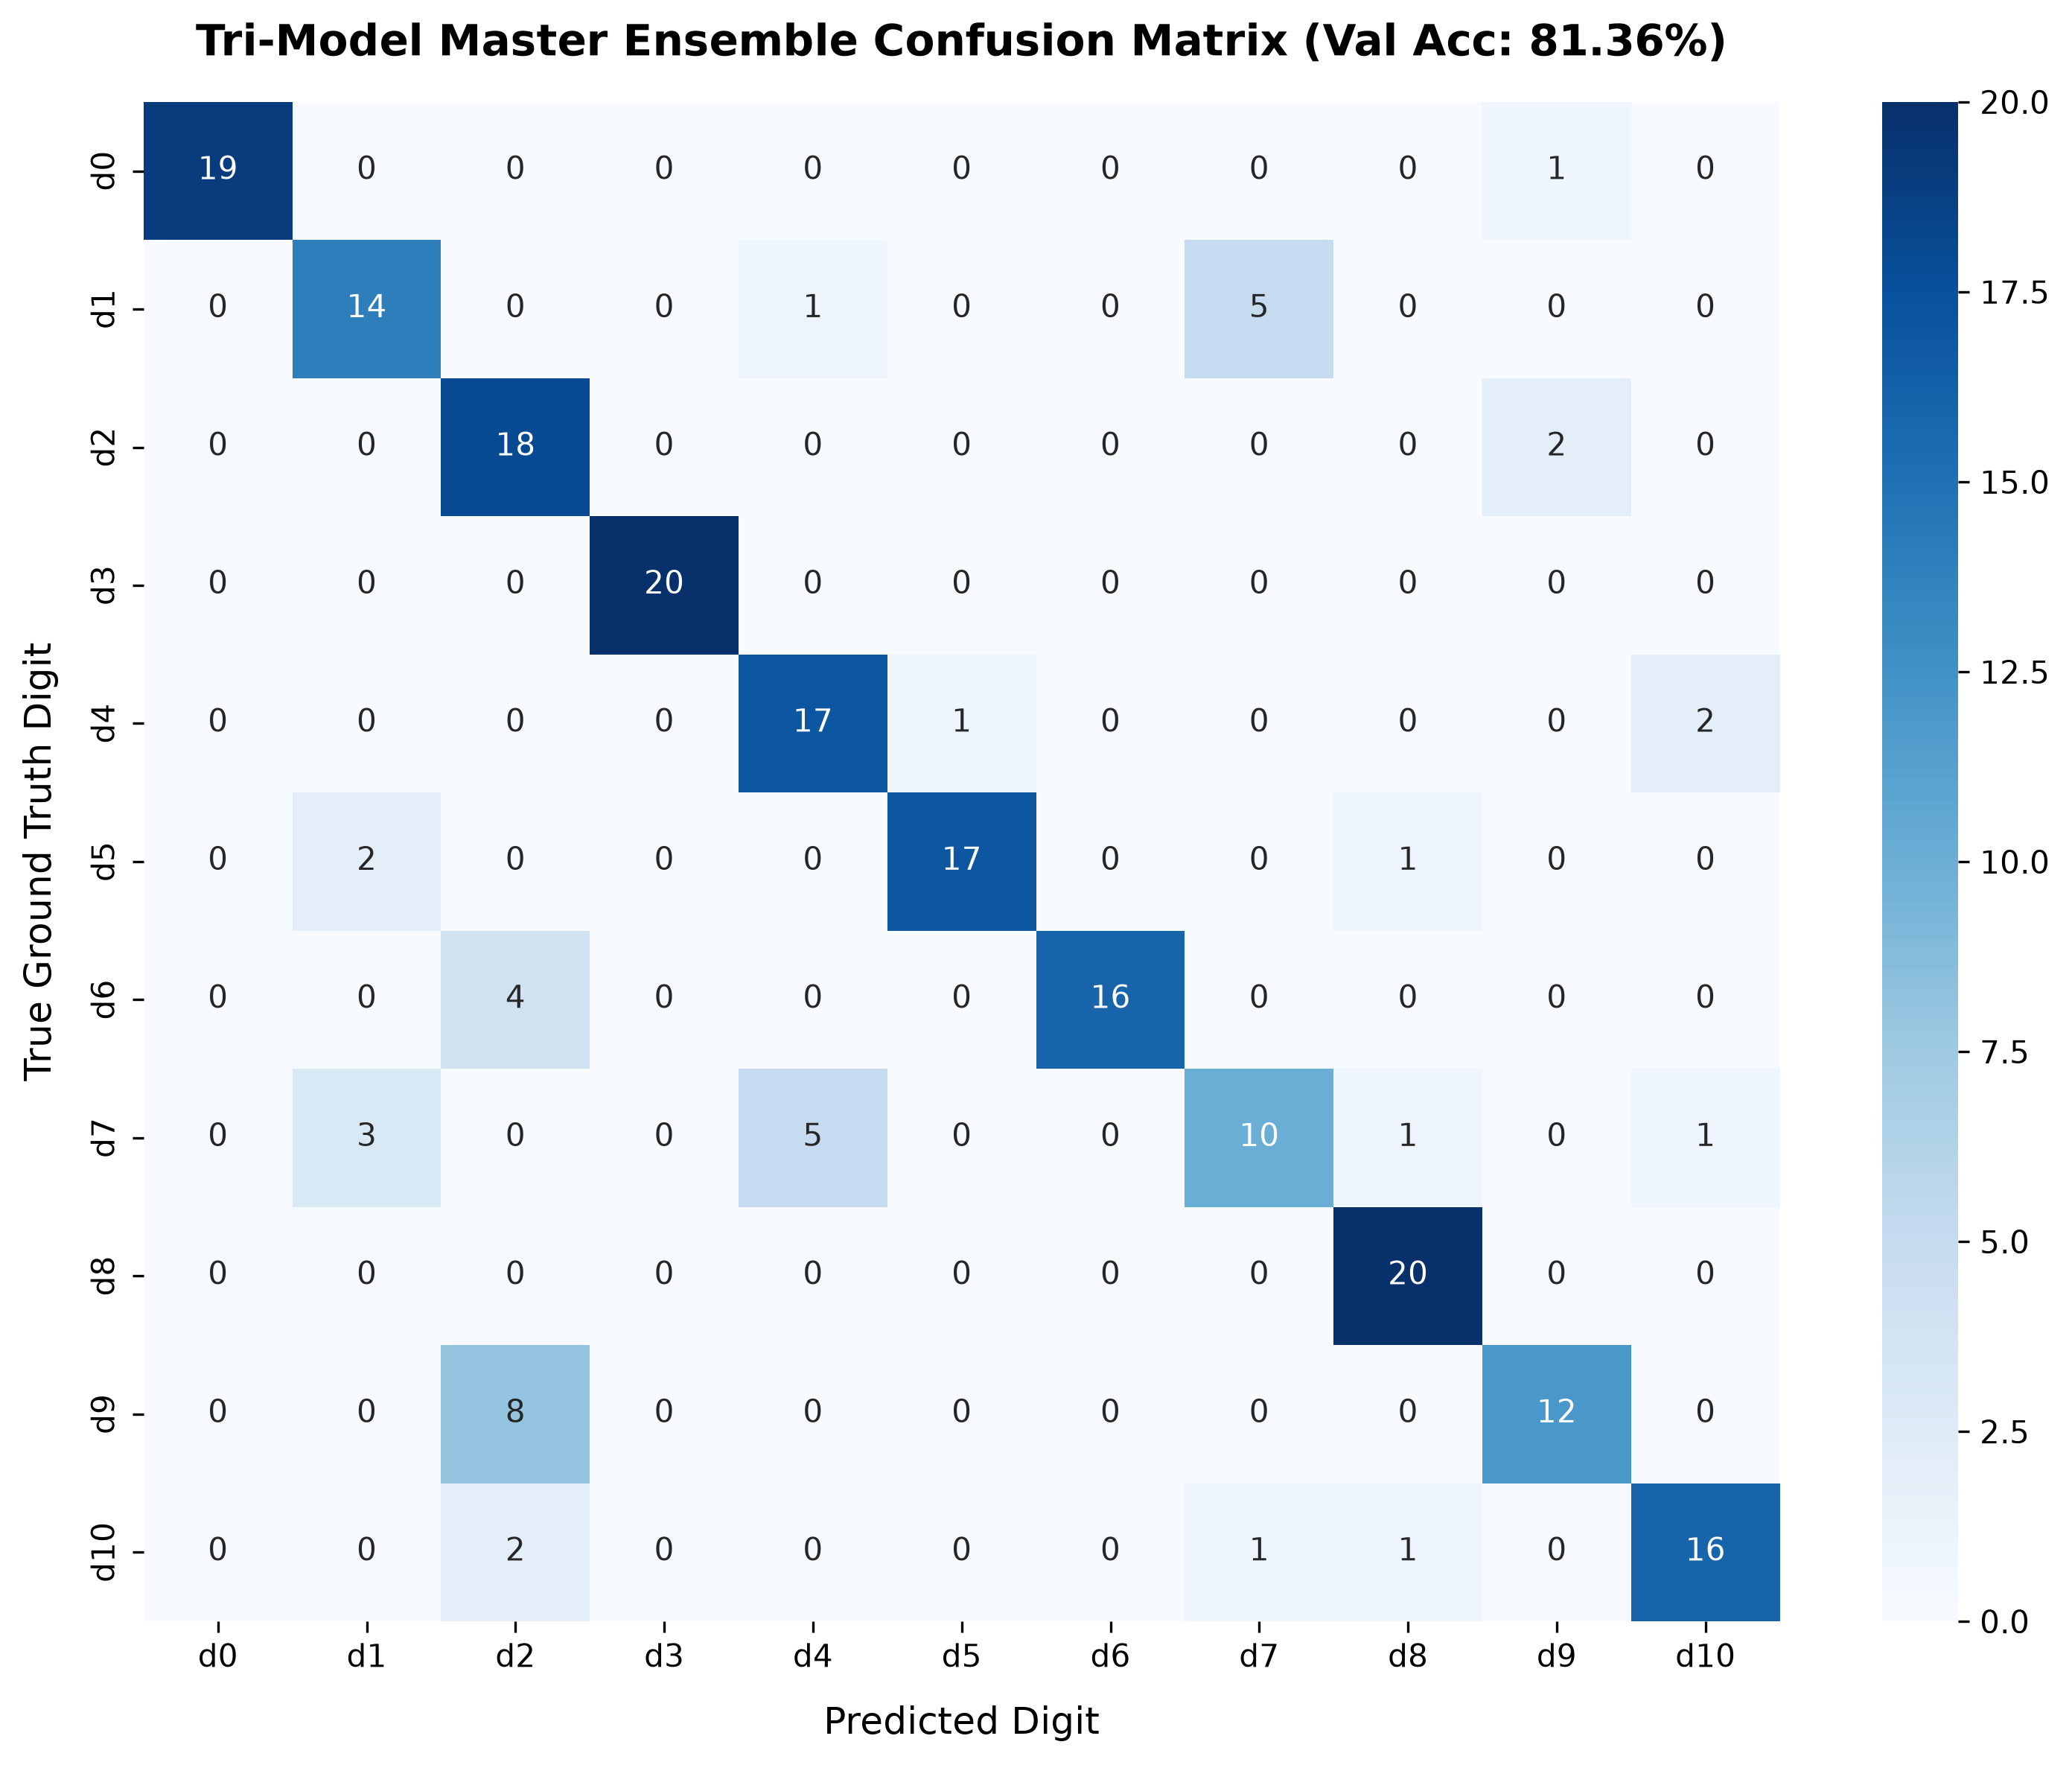

Saved confusion matrix plot to: /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/ensemble_tri_model_80_20/confusion_matrix_ensemble.png


In [12]:
cm = confusion_matrix(y_val, preds_opt)
fig, ax = plt.subplots(figsize=(10, 8), dpi=300)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[f"d{i}" for i in range(11)],
            yticklabels=[f"d{i}" for i in range(11)],
            ax=ax, cbar=True)
ax.set_title(f"Tri-Model Master Ensemble Confusion Matrix (Val Acc: {final_acc*100:.2f}%)", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Predicted Digit", fontsize=12, labelpad=10)
ax.set_ylabel("True Ground Truth Digit", fontsize=12, labelpad=10)
plt.tight_layout()
cm_path = RESULTS_DIR / "confusion_matrix_ensemble.png"
plt.savefig(cm_path)
plt.show()
print(f"Saved confusion matrix plot to: {cm_path}")


## 13. Persistence & Export of Results
Saving all metrics, per-speaker breakdowns, predictions, and reports to `results/ensemble_tri_model_80_20/`.


In [13]:
metrics = {
    "experiment_name": "tri_model_ensemble_effnet_mobilenet_triwindow_tta",
    "val_accuracy": float(final_acc),
    "correct_samples": int(np.sum(preds_opt == y_val)),
    "total_samples": int(N),
    "optimal_weights": {
        "w_effnet_nb19": float(wa_opt),
        "w_mobilenet_nb13": float(wb_opt),
        "w_triwindow_nb22": float(wc_opt)
    },
    "macro_f1": float(cls_rep_dict["macro avg"]["f1-score"]),
    "weighted_f1": float(cls_rep_dict["weighted avg"]["f1-score"]),
    "model_a_acc": float(acc_a),
    "model_b_acc": float(acc_b),
    "model_c_acc": float(acc_c),
    "oracle_ceiling_acc": float(oracle_acc),
    "per_speaker_accuracy": spk_breakdown
}

with open(RESULTS_DIR / "metrics_80_20.json", "w") as f:
    json.dump(metrics, f, indent=2)

with open(RESULTS_DIR / "classification_report.json", "w") as f:
    json.dump(cls_rep_dict, f, indent=2)

with open(RESULTS_DIR / "per_speaker_breakdown.json", "w") as f:
    json.dump(spk_breakdown, f, indent=2)

df_val.to_csv(RESULTS_DIR / "ensemble_utterance_predictions.csv", index=False)

print("=" * 80)
print(f"ALL TRI-MODEL ARTIFACTS EXPORTED SUCCESSFULLY TO: {RESULTS_DIR}")
print("=" * 80)


ALL TRI-MODEL ARTIFACTS EXPORTED SUCCESSFULLY TO: /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/ensemble_tri_model_80_20
